In [8]:
import pandas as pd

In [9]:
clust_res = pd.read_csv('data/clust-results.tsv', sep='\t', header=None)
clust_res.columns = ['type', 'cluster_id', 'query_length', 'similarity', 'strand', 0, 1, 'align_res', 'query_label', 'centroid_label']
clust_res = clust_res[['type', 'cluster_id', 'query_length', 'similarity', 'strand', 'align_res', 'query_label']]

In [10]:
cluster = clust_res[(clust_res['type'] == 'S') | (clust_res['type'] == 'H')]
cluster.head(20)

,type,cluster_id,query_length,similarity,strand,align_res,query_label
0,S,0,977,*,*,*,FJ008022.1
1,H,0,977,100.0,+,=,FJ008023.1
2,H,0,977,100.0,+,=,FJ008024.1
3,H,0,977,100.0,+,=,FJ008025.1
4,S,1,801,*,*,*,L04457.1
5,S,2,780,*,*,*,BK011976.1
6,H,2,780,100.0,+,=,NC_063789.1
7,S,3,777,*,*,*,AY894835.1
8,S,4,777,*,*,*,AY898627.1
9,H,4,777,100.0,+,=,AY898628.1


In [11]:
cluster.value_counts(subset='cluster_id').sort_values(ascending=False)

cluster_id
3       147
16      143
4       116
9       113
95       79
       ... 
1990      1
1991      1
1992      1
99        1
89        1
Name: count, Length: 2004, dtype: int64

In [12]:
db = pd.read_csv('data/cox2-db-filtered.csv', sep='\t')
db

,accession,creation_date,title,authors,sequence,sequence_length,organism_name,tax_id,cox2_start,cox2_end,cox2_strand
0,JF414552.1,12-DEC-2013,Pseudoperonospora cubensis isolate CDM-274 cyt...,"Mitchell,M.N., Ocamb,C.M., Grunwald,N.J., Manc...",GAACCTTGGCAATTAGGTTTTCAAGATCCTGCAACTCCCGTTATGG...,2164,Pseudoperonospora cubensis,143453,<0,726,1.0
1,JF414551.1,12-DEC-2013,Pseudoperonospora cubensis isolate CDM-273 cyt...,"Mitchell,M.N., Ocamb,C.M., Grunwald,N.J., Manc...",GAACCTTGGCAATTAGGTTTTCAAGATCCTGCAACTCCCGTTATGG...,2164,Pseudoperonospora cubensis,143453,<0,726,1.0
2,JF414550.1,12-DEC-2013,Pseudoperonospora cubensis isolate CDM-272 cyt...,"Mitchell,M.N., Ocamb,C.M., Grunwald,N.J., Manc...",GAACCTTGGCAATTAGGTTTTCAAGATCCTGCAACTCCCGTTATGG...,2164,Pseudoperonospora cubensis,143453,<0,726,1.0
3,JF414549.1,12-DEC-2013,Pseudoperonospora cubensis isolate CDM-269 cyt...,"Mitchell,M.N., Ocamb,C.M., Grunwald,N.J., Manc...",GAACCTTGGCAATTAGGTTTTCAAGATCCTGCAACTCCCGTTATGG...,2164,Pseudoperonospora cubensis,143453,<0,726,1.0
4,JF414548.1,12-DEC-2013,Pseudoperonospora cubensis isolate CDM-268 cyt...,"Mitchell,M.N., Ocamb,C.M., Grunwald,N.J., Manc...",GAACCTTGGCAATTAGGTTTTCAAGATCCTGCAACTCCCGTTATGG...,2164,Pseudoperonospora cubensis,143453,<0,726,1.0
...,...,...,...,...,...,...,...,...,...,...,...
6465,OR094655.1,28-AUG-2023,Peronospora belbahrii isolate p15-1 cytochrome...,"Wang,C.-F. and Hong,C.-F.",AAGATCCAGCAACTCCAGTTATGGAAGGTATTATTAACTTTCACCA...,564,Peronospora belbahrii,622444,<0,>564,1.0
6466,OR094654.1,28-AUG-2023,Peronospora belbahrii isolate p14-1-1 cytochro...,"Wang,C.-F. and Hong,C.-F.",AAGATCCAGCAACTCCAGTTATGGAAGGTATTATTAACTTTCACCA...,600,Peronospora belbahrii,622444,<0,>600,1.0
6467,OR094653.1,28-AUG-2023,Peronospora belbahrii isolate p13-1 cytochrome...,"Wang,C.-F. and Hong,C.-F.",CAAGATCCAGCAACTCCAGTTATGGAAGGTATTATTAACTTTCACC...,564,Peronospora belbahrii,622444,<0,>564,1.0
6468,OR094652.1,28-AUG-2023,Peronospora belbahrii isolate p12-1 cytochrome...,"Wang,C.-F. and Hong,C.-F.",AAGATCCAGCAACTCCAGTTATGGAAGGTATTATTAACTTTCACCA...,601,Peronospora belbahrii,622444,<0,>601,1.0


In [13]:
merged = db.merge(cluster, how='left', left_on='accession', right_on='query_label')
merged['trimed_seq_len'] = merged['sequence'].str.len()
merged

,accession,creation_date,title,authors,sequence,sequence_length,organism_name,tax_id,cox2_start,cox2_end,cox2_strand,type,cluster_id,query_length,similarity,strand,align_res,query_label,trimed_seq_len
0,JF414552.1,12-DEC-2013,Pseudoperonospora cubensis isolate CDM-274 cyt...,"Mitchell,M.N., Ocamb,C.M., Grunwald,N.J., Manc...",GAACCTTGGCAATTAGGTTTTCAAGATCCTGCAACTCCCGTTATGG...,2164,Pseudoperonospora cubensis,143453,<0,726,1.0,S,104,726,*,*,*,JF414552.1,726
1,JF414551.1,12-DEC-2013,Pseudoperonospora cubensis isolate CDM-273 cyt...,"Mitchell,M.N., Ocamb,C.M., Grunwald,N.J., Manc...",GAACCTTGGCAATTAGGTTTTCAAGATCCTGCAACTCCCGTTATGG...,2164,Pseudoperonospora cubensis,143453,<0,726,1.0,S,103,726,*,*,*,JF414551.1,726
2,JF414550.1,12-DEC-2013,Pseudoperonospora cubensis isolate CDM-272 cyt...,"Mitchell,M.N., Ocamb,C.M., Grunwald,N.J., Manc...",GAACCTTGGCAATTAGGTTTTCAAGATCCTGCAACTCCCGTTATGG...,2164,Pseudoperonospora cubensis,143453,<0,726,1.0,S,102,726,*,*,*,JF414550.1,726
3,JF414549.1,12-DEC-2013,Pseudoperonospora cubensis isolate CDM-269 cyt...,"Mitchell,M.N., Ocamb,C.M., Grunwald,N.J., Manc...",GAACCTTGGCAATTAGGTTTTCAAGATCCTGCAACTCCCGTTATGG...,2164,Pseudoperonospora cubensis,143453,<0,726,1.0,S,101,726,*,*,*,JF414549.1,726
4,JF414548.1,12-DEC-2013,Pseudoperonospora cubensis isolate CDM-268 cyt...,"Mitchell,M.N., Ocamb,C.M., Grunwald,N.J., Manc...",GAACCTTGGCAATTAGGTTTTCAAGATCCTGCAACTCCCGTTATGG...,2164,Pseudoperonospora cubensis,143453,<0,726,1.0,H,95,726,100.0,+,=,JF414548.1,726
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6465,OR094655.1,28-AUG-2023,Peronospora belbahrii isolate p15-1 cytochrome...,"Wang,C.-F. and Hong,C.-F.",AAGATCCAGCAACTCCAGTTATGGAAGGTATTATTAACTTTCACCA...,564,Peronospora belbahrii,622444,<0,>564,1.0,H,666,564,100.0,+,=,OR094655.1,564
6466,OR094654.1,28-AUG-2023,Peronospora belbahrii isolate p14-1-1 cytochro...,"Wang,C.-F. and Hong,C.-F.",AAGATCCAGCAACTCCAGTTATGGAAGGTATTATTAACTTTCACCA...,600,Peronospora belbahrii,622444,<0,>600,1.0,H,666,600,100.0,+,=,OR094654.1,600
6467,OR094653.1,28-AUG-2023,Peronospora belbahrii isolate p13-1 cytochrome...,"Wang,C.-F. and Hong,C.-F.",CAAGATCCAGCAACTCCAGTTATGGAAGGTATTATTAACTTTCACC...,564,Peronospora belbahrii,622444,<0,>564,1.0,H,808,564,100.0,+,=,OR094653.1,564
6468,OR094652.1,28-AUG-2023,Peronospora belbahrii isolate p12-1 cytochrome...,"Wang,C.-F. and Hong,C.-F.",AAGATCCAGCAACTCCAGTTATGGAAGGTATTATTAACTTTCACCA...,601,Peronospora belbahrii,622444,<0,>601,1.0,S,808,601,*,*,*,OR094652.1,601


In [14]:
#merged_groups = merged.groupby(by='cluster_id').apply(lambda group: group.sort_values('trimed_seq_len', ascending=False))
#filtered_df = merged[merged.groupby('cluster_id')['tax_id'].transform('nunique') > 1]
#filtered_df.to_csv('heterogenous-cluster.csv')
#merged_groups

In [15]:
df_sorted = merged.sort_values(by=['cluster_id', 'tax_id', 'trimed_seq_len'], ascending=[True, True, False])
df_sorted

,accession,creation_date,title,authors,sequence,sequence_length,organism_name,tax_id,cox2_start,cox2_end,cox2_strand,type,cluster_id,query_length,similarity,strand,align_res,query_label,trimed_seq_len
873,GU221959.1,25-JUL-2016,Phytophthora capsici isolate P3375 cytochrome ...,"Martin,F. and Radmer,L.",ATGGAAGGTATTATAAATTTTCATCATGATTTAATGTTTTTTTTAA...,996,Phytophthora capsici,4784,<0,684,1.0,H,0,684,100.0,+,=,GU221959.1,684
3478,JF771324.1,25-JUL-2016,Phytophthora capsici isolate P11620 cytochrome...,"Martin,F. and Radmer,L.",ATGGAAGGTATTATAAATTTTCATCATGATTTAATGTTTTTTTTAA...,934,Phytophthora capsici,4784,<0,684,1.0,H,0,684,100.0,+,=,JF771324.1,684
3506,JF771296.1,25-JUL-2016,Phytophthora capsici isolate P3490 cytochrome ...,"Martin,F. and Radmer,L.",ATGGAAGGTATTATAAATTTTCATCATGATTTAATGTTTTTTTTAA...,934,Phytophthora capsici,4784,<0,684,1.0,H,0,684,100.0,+,=,JF771296.1,684
3513,JF771289.1,25-JUL-2016,Phytophthora capsici isolate P1503 cytochrome ...,"Martin,F. and Radmer,L.",ATGGAAGGTATTATAAATTTTCATCATGATTTAATGTTTTTTTTAA...,934,Phytophthora capsici,4784,<0,684,1.0,H,0,684,100.0,+,=,JF771289.1,684
4213,JF771284.1,25-JUL-2016,Phytophthora capsici isolate P1037 cytochrome ...,"Martin,F. and Radmer,L.",ATGGAAGGTATTATAAATTTTCATCATGATTTAATGTTTTTTTTAA...,934,Phytophthora capsici,4784,<0,684,1.0,H,0,684,100.0,+,=,JF771284.1,684
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1550,MK067061.1,01-DEC-2020,Plasmopara elegantissima voucher KUS-F23341 cy...,"Choi,Y.J., Gorg,M., Shin,H.D. and Thines,M.",GTATTGGAGTTATGAATATTCAGATAATTTAGAATTTTCAGACGAA...,203,Plasmopara elegantissima,2575762,<0,>203,1.0,H,2003,203,100.0,+,=,MK067061.1,203
1551,MK067060.1,01-DEC-2020,Plasmopara elegantissima voucher KUS-F21824 cy...,"Choi,Y.J., Gorg,M., Shin,H.D. and Thines,M.",GTATTGGAGTTATGAATATTCAGATAATTTAGAATTTTCAGACGAA...,203,Plasmopara elegantissima,2575762,<0,>203,1.0,H,2003,203,100.0,+,=,MK067060.1,203
1554,MK067057.1,01-DEC-2020,Plasmopara elegantissima voucher KUS-F20250 cy...,"Choi,Y.J., Gorg,M., Shin,H.D. and Thines,M.",GTATTGGAGTTATGAATATTCAGATAATTTAGAATTTTCAGACGAA...,203,Plasmopara elegantissima,2575762,<0,>203,1.0,H,2003,203,100.0,+,=,MK067057.1,203
1555,MK067056.1,01-DEC-2020,Plasmopara elegantissima voucher KUS-F19566 cy...,"Choi,Y.J., Gorg,M., Shin,H.D. and Thines,M.",GTATTGGAGTTATGAATATTCAGATAATTTAGAATTTTCAGACGAA...,203,Plasmopara elegantissima,2575762,<0,>203,1.0,H,2003,203,100.0,+,=,MK067056.1,203


In [16]:
def filter_func(group: pd.DataFrame):
    # only keep identical sequences if they are from different species
    # Removes identical (but potentially shorter) sequences from the same species
    # ==> Remove redundant sequences that don't give any new information
    # PRE: each group is sorted (desc) by trimed_seq_len
    if group.shape[0] == 1:
        return group
    subgroup = group.groupby('tax_id', group_keys=False)
    return subgroup.apply(lambda sub: sub.iloc[0])

filtered_df = df_sorted.groupby('cluster_id', group_keys=False).apply(filter_func)
#filtered_df = df_sorted
filtered_df

/tmp/ipykernel_1592622/2595131638.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return subgroup.apply(lambda sub: sub.iloc[0])
/tmp/ipykernel_1592622/2595131638.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return subgroup.apply(lambda sub: sub.iloc[0])
/tmp/ipykernel_1592622/2595131638.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated

,accession,creation_date,title,authors,sequence,sequence_length,organism_name,tax_id,cox2_start,cox2_end,cox2_strand,type,cluster_id,query_length,similarity,strand,align_res,query_label,trimed_seq_len
4784,GU221959.1,25-JUL-2016,Phytophthora capsici isolate P3375 cytochrome ...,"Martin,F. and Radmer,L.",ATGGAAGGTATTATAAATTTTCATCATGATTTAATGTTTTTTTTAA...,996,Phytophthora capsici,4784,<0,684,1.0,H,0,684,100.0,+,=,GU221959.1,684
132615,FJ008025.1,26-JUL-2016,Phytophthora glovera isolate 11099 cytochrome ...,"Abad,Z.G., Ivors,K.L., Gallup,C.A., Abad,J.A. ...",ATGGAAGGTATTATAAATTTTCATCATGATTTAATGTTTTTTTTAA...,977,Phytophthora gloveri,132615,0,977,1.0,H,0,977,100.0,+,=,FJ008025.1,977
4788,L04457.1,25-JUL-2016,Phytophthora megasperma cytochrome c oxidase s...,"Shumard-Hudspeth,D.S. and Hudspeth,M.E.",ATGACAATCACAAATTATATCAACAATCAATTCACTTTTTTAGATA...,3572,Phytophthora megasperma,4788,793,1594,1.0,S,1,801,*,*,*,L04457.1,801
272952,NC_063789.1,13-APR-2023,Hyaloperonospora arabidopsidis isolate Noks1 m...,"Winkworth,R.C., Neal,G., Ogas,R.A., Nelson,B.C...",ATGGTAATCAAAAATTATATAATAGATAAGCAATCTACTTTTTTAG...,38797,Hyaloperonospora arabidopsidis,272952,24700,25480,1.0,H,2,780,100.0,+,=,NC_063789.1,780
4787,NC_002387.1,03-APR-2023,"Phytophthora infestans mitochondrion, complete...","Paquin,B., Laforest,M.J., Forget,L., Roewer,I....",ATGACAATAACAAATTATATAAATAATCAATTTACTTTTTTAGATA...,37957,Phytophthora infestans,4787,7660,8437,1.0,H,3,777,100.0,+,=,NC_002387.1,777
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4163,HM628758.1,07-DEC-2017,Plasmopara viticola strain U366 voucher HUH ex...,"Schroeder,S., Telle,S., Nick,P. and Thines,M.",TACTGGAGTTATGAATATTCCGATAATTTAGAGTTTTCAGATGAAC...,248,Plasmopara viticola,143451,<0,>248,1.0,S,1999,248,*,*,*,HM628758.1,248
2476,KP979650.1,30-MAR-2015,Peronosclerospora sorghi isolate 3BSJBPS1 cyto...,"Rustiani,U.S., Sinaga,M.S., Wiyono,S. and Hida...",TCCAGCAACTCCAGTTATGGAAGGTATTATTAATTTTCATCATGAT...,241,Peronosclerospora sorghi,230839,<0,>241,1.0,S,2000,241,*,*,*,KP979650.1,241
3056,EU595782.1,26-JUL-2016,Phytophthora sp. 4E4 cytochrome c oxidase subu...,"Hong,C., Gallegly,M.E., Richardson,P.A., Kong,...",CCATGGTATTGGAGTTACGAATATTCAGATAATTTAGAATTTTCAG...,210,Phytophthora irrigata,565287,<0,>210,1.0,S,2001,210,*,*,*,EU595782.1,210
2019374,MF372728.1,23-JUL-2017,Plasmopara destructor voucher GLM-F107554 cyto...,"Goerg,M., Ploch,S., Kruse,J., Kummer,V., Runge...",ACGGTATTGCCCAAGAATGTAAAACATCTGATGCAGTAATTAATAC...,203,Plasmopara destructor,2019374,<0,>203,-1.0,H,2002,203,100.0,+,=,MF372728.1,203


In [17]:
filtered_df.value_counts('tax_id').sort_values(ascending=False)

tax_id
114742     100
65357       67
907947      66
36331       40
143453      37
          ... 
436079       1
436701       1
3073792      1
3073794      1
3090892      1
Name: count, Length: 803, dtype: int64

In [18]:
filtered_df.to_csv('data/cox2-db-clust.csv', index=False, sep='\t')

In [19]:
filtered_df[filtered_df['tax_id'] == 4787].reset_index()

,index,accession,creation_date,title,authors,sequence,sequence_length,organism_name,tax_id,cox2_start,cox2_end,cox2_strand,type,cluster_id,query_length,similarity,strand,align_res,query_label,trimed_seq_len
0,4787,NC_002387.1,03-APR-2023,"Phytophthora infestans mitochondrion, complete...","Paquin,B., Laforest,M.J., Forget,L., Roewer,I....",ATGACAATAACAAATTATATAAATAATCAATTTACTTTTTTAGATA...,37957,Phytophthora infestans,4787,7660,8437,1.0,H,3,777,100.0,+,=,NC_002387.1,777
1,4787,MH286887.1,19-MAR-2019,Phytophthora infestans voucher IT199999 mitoch...,"Cho,K.-S., Choi,J.-G., Cho,J.-H., Im,J.-S., Pa...",TTATACATTAAAATCAAAATTAATTTTATTTTTTAACCAAGTTAAA...,39872,Phytophthora infestans,4787,38640,39417,-1.0,H,4,777,100.0,-,=,MH286887.1,777
2,4787,JF771467.1,25-JUL-2016,Phytophthora infestans isolate P7722 cytochrom...,"Martin,F. and Radmer,L.",ATGGAAGGTATTATTAACTTTCACCATGATTTAATGTTTTTTTTAA...,908,Phytophthora infestans,4787,<0,684,1.0,H,414,684,100.0,+,=,JF771467.1,684
3,3312,JF771491.1,25-JUL-2016,Phytophthora infestans isolate P15168 cytochro...,"Martin,F. and Radmer,L.",ATGGAAGGTATTATTAACTTTCACCATGATTTAATGTTTTTTTTAA...,911,Phytophthora infestans,4787,<0,684,1.0,S,462,684,*,*,*,JF771491.1,684
4,241,JQ439449.1,31-DEC-2012,Phytophthora infestans isolate P10646 cytochro...,"Martin,F. and Radmer,L.",ATGGAAGGTATTATTAACTTTCACCATGATTTAATGTTTTTTTTAA...,911,Phytophthora infestans,4787,<0,684,1.0,S,480,684,*,*,*,JQ439449.1,684
5,4787,GQ261002.1,24-JUL-2016,Phytophthora infestans culture-collection CIP<...,"Oliva,R.F., Kroon,L.P.N.M., Chacon,G., Flier,W...",ATTTAATGTTTTTTTTAATTATGATTACTGTGTTTGTTTGTTGGAT...,664,Phytophthora infestans,4787,<0,656,1.0,H,538,656,100.0,+,=,GQ261002.1,656
6,4787,MH760279.1,24-APR-2019,Phytophthora infestans strain 2009-7654A cytoc...,"Maizatul-Suriza,M., Dickinson,M. and Idris,A.S.",TTTGGCAATTAGGTTTTCAAGATCCAGCAACTCCAGTTATGGAAGG...,621,Phytophthora infestans,4787,<0,>621,1.0,H,682,621,100.0,+,=,MH760279.1,621
7,6280,PP356592.1,27-FEB-2024,Phytophthora infestans cytochrome oxidase subu...,"Azimova,N.S., Qobilov,F.B., Nazirov,M.M., Khal...",TTTCAAGATCCAGCAACTCCAGTTATGGAAGGTATTATTAACTTTC...,583,Phytophthora infestans,4787,<0,>583,1.0,S,914,583,*,*,*,PP356592.1,583
8,3981,KJ654169.1,12-MAR-2019,Phytophthora infestans isolate O17 cytochrome ...,"Choi,Y.J., Beakes,G., Glockling,S., Kruse,J., ...",AGCAACTCCAGTTATGGAAGGTATTATTAACTTTCACCATGATTTA...,581,Phytophthora infestans,4787,<0,>581,1.0,S,991,581,*,*,*,KJ654169.1,581


array([[<Axes: title={'center': 'creation_date'}>]], dtype=object)

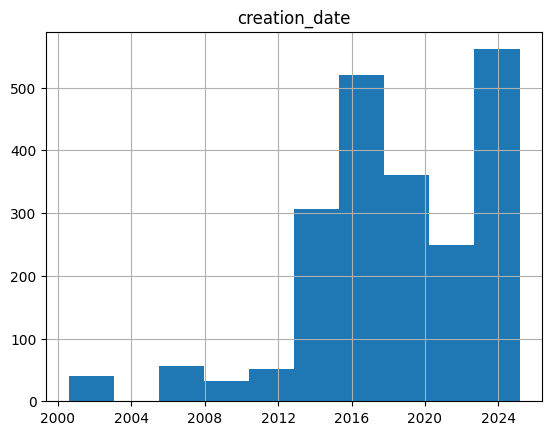

In [20]:
from datetime import datetime
filtered_df['creation_date'] = filtered_df['creation_date'].apply(lambda x: datetime.strptime(x, "%d-%b-%Y"))
filtered_df.hist('creation_date')

array([[<Axes: title={'center': 'trimed_seq_len'}>]], dtype=object)

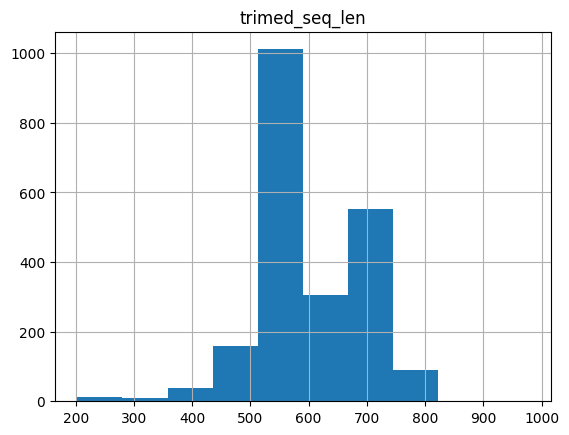

In [21]:
filtered_df.hist('trimed_seq_len')

In [22]:
def sanitize_org_name(org_name: str) -> str:
    org_name_arr = org_name.split(' ')
    to_remove = ['x', 'var.', 'var', 'aff.', 'aff', 'cf.', 'cf']
    for s in to_remove:
        try:
            org_name_arr.remove(s)
        except ValueError:
            pass
    return ' '.join(org_name_arr[:2])


In [23]:
filtered_df['tax_id_sanitized'] = filtered_df['tax_id']
filtered_df['organism_name_sanitized'] = filtered_df['organism_name'].apply(sanitize_org_name)
def fix_tax_id(row: pd.Series):
    if row['organism_name_sanitized'] == row['organism_name']:
        return row['tax_id']
    if row['organism_name_sanitized'] in filtered_df['organism_name'].unique():
        new_tax_id = filtered_df.loc[filtered_df['organism_name'] == row['organism_name_sanitized']]['tax_id'].iloc[0]
        return new_tax_id
    return row['tax_id']

filtered_df['tax_id_sanitized'] = filtered_df.apply(fix_tax_id, axis=1)
sane_species = filtered_df[filtered_df['organism_name'].str.count(' ') == 1]
dup_species = filtered_df[filtered_df['organism_name'].str.count(' ') > 1]
dup_species.to_csv('dup-species.csv')
filtered_df.value_counts('tax_id_sanitized')

tax_id_sanitized
114742    100
65357      67
907947     66
36331      40
143453     37
         ... 
445398      1
442665      1
436701      1
436079      1
565288      1
Name: count, Length: 764, dtype: int64

In [24]:
tax_db = pd.read_csv('data/tax-filtered.csv', sep='\t')
seq_and_tax = filtered_df.merge(tax_db, right_on='tax_id', left_on='tax_id_sanitized', how='inner')
# remove sequences with unknown taxonomy info
#seq_and_tax = seq_and_tax.dropna(subset='genus')
seq_and_tax

,accession,creation_date,title,authors,sequence,sequence_length,organism_name,tax_id_x,cox2_start,cox2_end,...,organism_name_sanitized,tax_id_y,species,domain,kingdom,phylum,class,order,family,genus
0,GU221959.1,2016-07-25,Phytophthora capsici isolate P3375 cytochrome ...,"Martin,F. and Radmer,L.",ATGGAAGGTATTATAAATTTTCATCATGATTTAATGTTTTTTTTAA...,996,Phytophthora capsici,4784,<0,684,...,Phytophthora capsici,4784,Phytophthora capsici,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora
1,FJ008025.1,2016-07-26,Phytophthora glovera isolate 11099 cytochrome ...,"Abad,Z.G., Ivors,K.L., Gallup,C.A., Abad,J.A. ...",ATGGAAGGTATTATAAATTTTCATCATGATTTAATGTTTTTTTTAA...,977,Phytophthora gloveri,132615,0,977,...,Phytophthora gloveri,132615,Phytophthora gloveri,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora
2,L04457.1,2016-07-25,Phytophthora megasperma cytochrome c oxidase s...,"Shumard-Hudspeth,D.S. and Hudspeth,M.E.",ATGACAATCACAAATTATATCAACAATCAATTCACTTTTTTAGATA...,3572,Phytophthora megasperma,4788,793,1594,...,Phytophthora megasperma,4788,Phytophthora megasperma,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora
3,NC_063789.1,2023-04-13,Hyaloperonospora arabidopsidis isolate Noks1 m...,"Winkworth,R.C., Neal,G., Ogas,R.A., Nelson,B.C...",ATGGTAATCAAAAATTATATAATAGATAAGCAATCTACTTTTTTAG...,38797,Hyaloperonospora arabidopsidis,272952,24700,25480,...,Hyaloperonospora arabidopsidis,272952,Hyaloperonospora arabidopsidis,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Hyaloperonospora
4,NC_002387.1,2023-04-03,"Phytophthora infestans mitochondrion, complete...","Paquin,B., Laforest,M.J., Forget,L., Roewer,I....",ATGACAATAACAAATTATATAAATAATCAATTTACTTTTTTAGATA...,37957,Phytophthora infestans,4787,7660,8437,...,Phytophthora infestans,4787,Phytophthora infestans,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2165,HM628758.1,2017-12-07,Plasmopara viticola strain U366 voucher HUH ex...,"Schroeder,S., Telle,S., Nick,P. and Thines,M.",TACTGGAGTTATGAATATTCCGATAATTTAGAGTTTTCAGATGAAC...,248,Plasmopara viticola,143451,<0,>248,...,Plasmopara viticola,143451,Plasmopara viticola,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Plasmopara
2166,KP979650.1,2015-03-30,Peronosclerospora sorghi isolate 3BSJBPS1 cyto...,"Rustiani,U.S., Sinaga,M.S., Wiyono,S. and Hida...",TCCAGCAACTCCAGTTATGGAAGGTATTATTAATTTTCATCATGAT...,241,Peronosclerospora sorghi,230839,<0,>241,...,Peronosclerospora sorghi,230839,Peronosclerospora sorghi,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Peronosclerospora
2167,EU595782.1,2016-07-26,Phytophthora sp. 4E4 cytochrome c oxidase subu...,"Hong,C., Gallegly,M.E., Richardson,P.A., Kong,...",CCATGGTATTGGAGTTACGAATATTCAGATAATTTAGAATTTTCAG...,210,Phytophthora irrigata,565287,<0,>210,...,Phytophthora irrigata,565287,Phytophthora irrigata,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora
2168,MF372728.1,2017-07-23,Plasmopara destructor voucher GLM-F107554 cyto...,"Goerg,M., Ploch,S., Kruse,J., Kummer,V., Runge...",ACGGTATTGCCCAAGAATGTAAAACATCTGATGCAGTAATTAATAC...,203,Plasmopara destructor,2019374,<0,>203,...,Plasmopara destructor,2019374,Plasmopara destructor,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Plasmopara


In [25]:
seq_and_tax.to_csv('seq-and-tax-clust.csv')

### Construct SINTAX compatible db

In [26]:
from Bio.Seq import Seq
with open('data/cox2-db-clust.fa', 'w') as out:
    for index, row in seq_and_tax.iterrows():
        print(f'>{row["accession"]};tax=d:{row["domain"]};k:{row["kingdom"]};p:{row["phylum"]};c:{row["class"]};o:{row["order"]};f:{row["family"]};g:{row["genus"]};s:{row["organism_name_sanitized"].replace(" ", "+")}', file=out)
        if int(row['cox2_strand']) == -1:
            seq = Seq(row['sequence'])
            print(seq.reverse_complement(), file=out)
        else:
            print(row['sequence'], file=out)

In [27]:
seq_and_tax['sequence_trimmed_len'] = seq_and_tax['sequence'].apply(len)
seq_and_tax

,accession,creation_date,title,authors,sequence,sequence_length,organism_name,tax_id_x,cox2_start,cox2_end,...,tax_id_y,species,domain,kingdom,phylum,class,order,family,genus,sequence_trimmed_len
0,GU221959.1,2016-07-25,Phytophthora capsici isolate P3375 cytochrome ...,"Martin,F. and Radmer,L.",ATGGAAGGTATTATAAATTTTCATCATGATTTAATGTTTTTTTTAA...,996,Phytophthora capsici,4784,<0,684,...,4784,Phytophthora capsici,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora,684
1,FJ008025.1,2016-07-26,Phytophthora glovera isolate 11099 cytochrome ...,"Abad,Z.G., Ivors,K.L., Gallup,C.A., Abad,J.A. ...",ATGGAAGGTATTATAAATTTTCATCATGATTTAATGTTTTTTTTAA...,977,Phytophthora gloveri,132615,0,977,...,132615,Phytophthora gloveri,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora,977
2,L04457.1,2016-07-25,Phytophthora megasperma cytochrome c oxidase s...,"Shumard-Hudspeth,D.S. and Hudspeth,M.E.",ATGACAATCACAAATTATATCAACAATCAATTCACTTTTTTAGATA...,3572,Phytophthora megasperma,4788,793,1594,...,4788,Phytophthora megasperma,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora,801
3,NC_063789.1,2023-04-13,Hyaloperonospora arabidopsidis isolate Noks1 m...,"Winkworth,R.C., Neal,G., Ogas,R.A., Nelson,B.C...",ATGGTAATCAAAAATTATATAATAGATAAGCAATCTACTTTTTTAG...,38797,Hyaloperonospora arabidopsidis,272952,24700,25480,...,272952,Hyaloperonospora arabidopsidis,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Hyaloperonospora,780
4,NC_002387.1,2023-04-03,"Phytophthora infestans mitochondrion, complete...","Paquin,B., Laforest,M.J., Forget,L., Roewer,I....",ATGACAATAACAAATTATATAAATAATCAATTTACTTTTTTAGATA...,37957,Phytophthora infestans,4787,7660,8437,...,4787,Phytophthora infestans,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora,777
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2165,HM628758.1,2017-12-07,Plasmopara viticola strain U366 voucher HUH ex...,"Schroeder,S., Telle,S., Nick,P. and Thines,M.",TACTGGAGTTATGAATATTCCGATAATTTAGAGTTTTCAGATGAAC...,248,Plasmopara viticola,143451,<0,>248,...,143451,Plasmopara viticola,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Plasmopara,248
2166,KP979650.1,2015-03-30,Peronosclerospora sorghi isolate 3BSJBPS1 cyto...,"Rustiani,U.S., Sinaga,M.S., Wiyono,S. and Hida...",TCCAGCAACTCCAGTTATGGAAGGTATTATTAATTTTCATCATGAT...,241,Peronosclerospora sorghi,230839,<0,>241,...,230839,Peronosclerospora sorghi,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Peronosclerospora,241
2167,EU595782.1,2016-07-26,Phytophthora sp. 4E4 cytochrome c oxidase subu...,"Hong,C., Gallegly,M.E., Richardson,P.A., Kong,...",CCATGGTATTGGAGTTACGAATATTCAGATAATTTAGAATTTTCAG...,210,Phytophthora irrigata,565287,<0,>210,...,565287,Phytophthora irrigata,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora,210
2168,MF372728.1,2017-07-23,Plasmopara destructor voucher GLM-F107554 cyto...,"Goerg,M., Ploch,S., Kruse,J., Kummer,V., Runge...",ACGGTATTGCCCAAGAATGTAAAACATCTGATGCAGTAATTAATAC...,203,Plasmopara destructor,2019374,<0,>203,...,2019374,Plasmopara destructor,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Plasmopara,203
